# 1. Imports y configuración

In [12]:
#!{sys.executable} -m pip install mne

  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.61.0 requires numpy<2.2,>=1.24, but you have numpy 2.4.6 which is incompatible.
tensorflow-intel 2.16.1 requires numpy<2.0.0,>=1.23.5; python_version <= "3.11", but you have numpy 2.4.6 which is incompatible.
tensorflow-intel 2.16.1 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<5.0.0dev,>=3.20.3, but you have protobuf 6.33.6 which is incompatible.
ydata-profiling 4.13.0 requires numpy<2.2,>=1.16.0, but you have numpy 2.4.6 which is incompatible.
ydata-profiling 4.13.0 requires scipy<1.14,>=1.4.1, but you have scipy 1.17.1 which is incompatible.

[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\User


   ---------------------------------------- 0.0/7.7 MB ? eta -:--:--
   ---------------------------------------- 7.7/7.7 MB 52.9 MB/s  0:00:00
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------  12.6/12.6 MB 71.6 MB/s eta 0:00:01
   ---------------------------------------- 12.6/12.6 MB 56.4 MB/s  0:00:00
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   ------------ --------------------------- 11.5/36.6 MB 55.5 MB/s eta 0:00:01
   --------------------- ------------------ 19.9/36.6 MB 46.6 MB/s eta 0:00:01
   --------------------------------- ------ 30.9/36.6 MB 47.9 MB/s eta 0:00:01
   ---------------------------------------  36.4/36.6 MB 47.3 MB/s eta 0:00:01
   ---------------------------------------- 36.6/36.6 MB 40.1 MB/s  0:00:00

  Attempting uninstall: numpy

    Found existing installation: numpy 1.26.4

   ---------------------------------------- 0/5 [numpy]
   -------------------------------

In [1]:
from pathlib import Path
import sys
import torch
import numpy as np
import matplotlib.pyplot as plt
import mne

# Proyecto
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

while not (PROJECT_ROOT / "src").is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError(
        f"No se encontró la carpeta 'src' desde {Path.cwd()}"
    )

sys.path.insert(0, str(PROJECT_ROOT))

print("PROJECT_ROOT:", PROJECT_ROOT)

from src.models.cnn import TinySleepNet, TinySleepNetConfig


# Clases del modelo
CLASS_NAMES = ["W", "N1", "N2", "N3", "REM"]

# Parámetros de la señal
SAMPLING_RATE = 100
EPOCH_SECONDS = 30
SAMPLES_PER_EPOCH = SAMPLING_RATE * EPOCH_SECONDS
SEQ_LENGTH = 15

print("Samples por época:", SAMPLES_PER_EPOCH)
print("Épocas por secuencia:", SEQ_LENGTH)

PROJECT_ROOT: C:\Users\danos\Documents\MAIA\Cursos\Semestre 4\Proyecto DS\proyecto-desarrollo-de-soluciones-G5
Samples por época: 3000
Épocas por secuencia: 15


# 2. Buscar los EDF

In [2]:
DATA_DIR = PROJECT_ROOT / "data" / "sleep-edfx"

edf_files = list(DATA_DIR.rglob("*.edf"))

print(f"EDF encontrados: {len(edf_files)}")

for path in edf_files[:20]:
    print(path)

EDF encontrados: 394
C:\Users\danos\Documents\MAIA\Cursos\Semestre 4\Proyecto DS\proyecto-desarrollo-de-soluciones-G5\data\sleep-edfx\sleep-cassette\SC4001E0-PSG.edf
C:\Users\danos\Documents\MAIA\Cursos\Semestre 4\Proyecto DS\proyecto-desarrollo-de-soluciones-G5\data\sleep-edfx\sleep-cassette\SC4001EC-Hypnogram.edf
C:\Users\danos\Documents\MAIA\Cursos\Semestre 4\Proyecto DS\proyecto-desarrollo-de-soluciones-G5\data\sleep-edfx\sleep-cassette\SC4002E0-PSG.edf
C:\Users\danos\Documents\MAIA\Cursos\Semestre 4\Proyecto DS\proyecto-desarrollo-de-soluciones-G5\data\sleep-edfx\sleep-cassette\SC4002EC-Hypnogram.edf
C:\Users\danos\Documents\MAIA\Cursos\Semestre 4\Proyecto DS\proyecto-desarrollo-de-soluciones-G5\data\sleep-edfx\sleep-cassette\SC4011E0-PSG.edf
C:\Users\danos\Documents\MAIA\Cursos\Semestre 4\Proyecto DS\proyecto-desarrollo-de-soluciones-G5\data\sleep-edfx\sleep-cassette\SC4011EH-Hypnogram.edf
C:\Users\danos\Documents\MAIA\Cursos\Semestre 4\Proyecto DS\proyecto-desarrollo-de-solucion

# 3. Cargar un PSG

In [3]:
PSG_PATH = edf_files[0]

raw = mne.io.read_raw_edf(
    PSG_PATH,
    preload=True,
    verbose=False
)

print(raw)
print("\nCanales:")
print(raw.ch_names)

C:\Users\danos\AppData\Local\Temp\ipykernel_25852\2796434259.py:3: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
C:\Users\danos\AppData\Local\Temp\ipykernel_25852\2796434259.py:3: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
C:\Users\danos\AppData\Local\Temp\ipykernel_25852\2796434259.py:3: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(


<RawEDF | SC4001E0-PSG.edf, 7 x 7950000 (79500.0 s), ~424.6 MiB, data loaded>

Canales:
['EEG Fpz-Cz', 'EEG Pz-Oz', 'EOG horizontal', 'Resp oro-nasal', 'EMG submental', 'Temp rectal', 'Event marker']


# 4. Identificar Fpz-Cz

In [4]:
fpz_cz_channels = [
    ch for ch in raw.ch_names
    if "Fpz-Cz" in ch or "FPZ-CZ" in ch.upper()
]

print(fpz_cz_channels)

['EEG Fpz-Cz']


In [5]:
CHANNEL = fpz_cz_channels[0]

eeg = raw.copy().pick([CHANNEL])

print(eeg)

<RawEDF | SC4001E0-PSG.edf, 1 x 7950000 (79500.0 s), ~60.7 MiB, data loaded>


# 5. Revisar la señal

Using matplotlib as 2D backend.
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


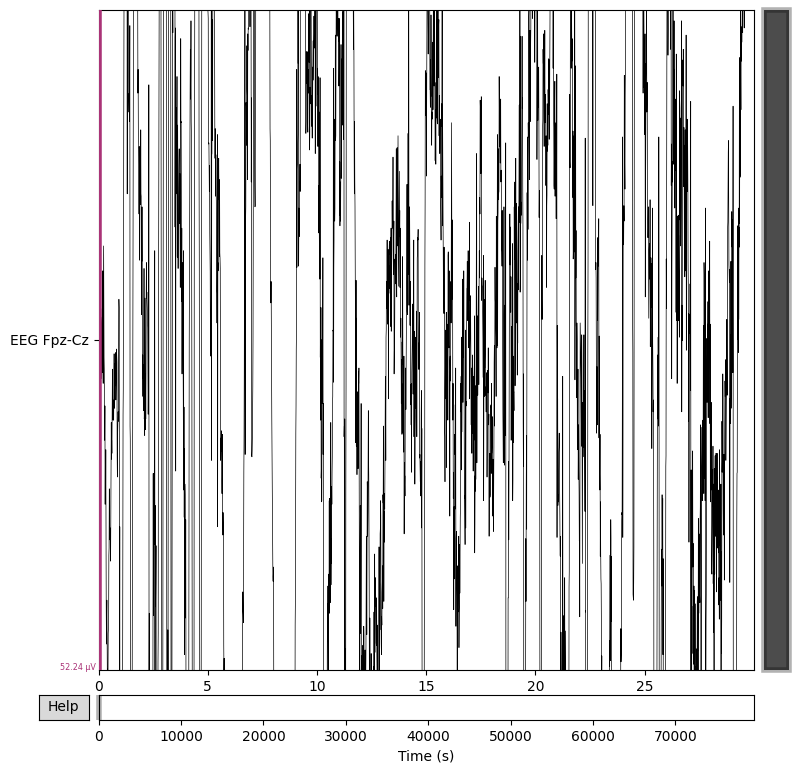

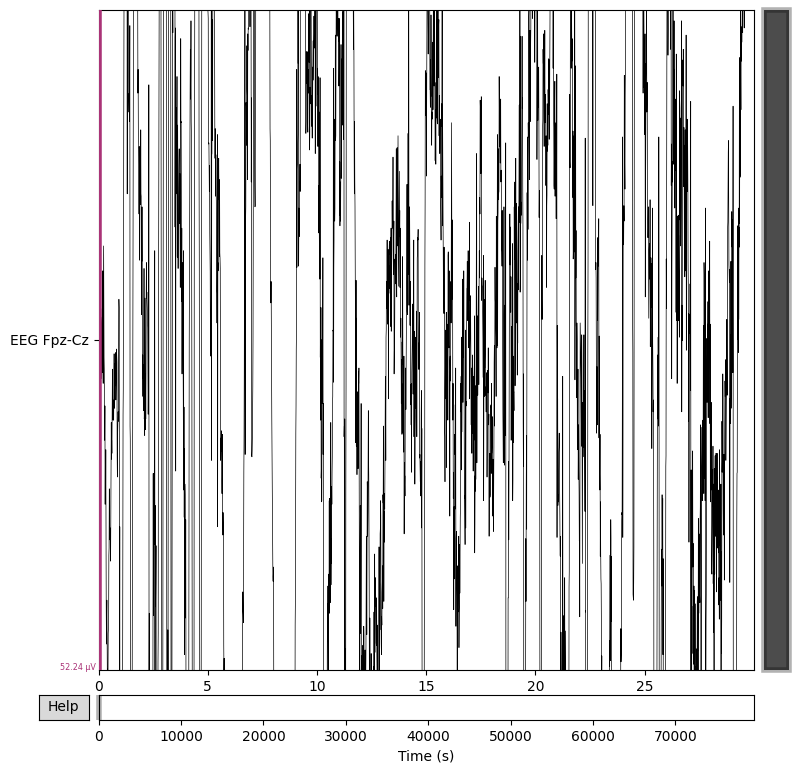

In [6]:
eeg.plot(
    duration=30,
    n_channels=1,
    scalings="auto"
)

# 6. Asegurar 100 Hz

In [7]:
print("Frecuencia original:", eeg.info["sfreq"])

Frecuencia original: 100.0


Si no fuera 100 Hz:

In [8]:
if eeg.info["sfreq"] != SAMPLING_RATE:
    eeg.resample(SAMPLING_RATE)

In [9]:
signal = eeg.get_data()[0]

print("Shape:", signal.shape)
print("Frecuencia:", eeg.info["sfreq"])

Shape: (7950000,)
Frecuencia: 100.0


# 7. Dividir en épocas de 30 segundos

In [10]:
n_epochs = len(signal) // SAMPLES_PER_EPOCH

signal = signal[:n_epochs * SAMPLES_PER_EPOCH]

epochs = signal.reshape(
    n_epochs,
    SAMPLES_PER_EPOCH
)

print("Número de épocas:", epochs.shape[0])
print("Shape:", epochs.shape)

Número de épocas: 2650
Shape: (2650, 3000)


# 8. Construir una secuencia de 15 épocas


In [11]:
sequence = epochs[:SEQ_LENGTH]

print(sequence.shape)

(15, 3000)


In [12]:
x = torch.tensor(
    sequence,
    dtype=torch.float32
)

x = x.unsqueeze(0).unsqueeze(2)

print(x.shape)

torch.Size([1, 15, 1, 3000])


# 9. Cargar el modelo desde MLflow

In [15]:
path = r"C:\Users\danos\Documents\tinysleepnet_final.pth"

checkpoint = torch.load(
    r"C:\Users\danos\AppData\Local\Temp\tmpb7m16i3_\tinysleepnet_final.pth.zip",
    map_location="cpu"
)
print(type(checkpoint))
print(checkpoint.keys() if isinstance(checkpoint, dict) else checkpoint)
state_dict = torch.load(
    r"C:\Users\danos\AppData\Local\Temp\tmpb7m16i3_\tinysleepnet_final.pth.zip",
    map_location="cpu"
)


<class 'collections.OrderedDict'>
odict_keys(['cnn.block1.conv.weight', 'cnn.block1.bn.weight', 'cnn.block1.bn.bias', 'cnn.block1.bn.running_mean', 'cnn.block1.bn.running_var', 'cnn.block1.bn.num_batches_tracked', 'cnn.block2.0.conv.weight', 'cnn.block2.0.bn.weight', 'cnn.block2.0.bn.bias', 'cnn.block2.0.bn.running_mean', 'cnn.block2.0.bn.running_var', 'cnn.block2.0.bn.num_batches_tracked', 'cnn.block2.1.conv.weight', 'cnn.block2.1.bn.weight', 'cnn.block2.1.bn.bias', 'cnn.block2.1.bn.running_mean', 'cnn.block2.1.bn.running_var', 'cnn.block2.1.bn.num_batches_tracked', 'cnn.block2.2.conv.weight', 'cnn.block2.2.bn.weight', 'cnn.block2.2.bn.bias', 'cnn.block2.2.bn.running_mean', 'cnn.block2.2.bn.running_var', 'cnn.block2.2.bn.num_batches_tracked', 'lstm.weight_ih_l0', 'lstm.weight_hh_l0', 'lstm.bias_ih_l0', 'lstm.bias_hh_l0', 'fc.weight', 'fc.bias'])


In [16]:

config = TinySleepNetConfig()

model = TinySleepNet(config)

model.load_state_dict(checkpoint)

model.eval()

TinySleepNet(
  (cnn): TinySleepNetCNN(
    (block1): _ConvBNReLU(
      (conv): Conv1d(1, 128, kernel_size=(50,), stride=(6,), padding=(25,), bias=False)
      (bn): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
    )
    (pool1): MaxPool1d(kernel_size=8, stride=8, padding=0, dilation=1, ceil_mode=False)
    (drop1): Dropout(p=0.5, inplace=False)
    (block2): Sequential(
      (0): _ConvBNReLU(
        (conv): Conv1d(128, 128, kernel_size=(8,), stride=(1,), padding=(4,), bias=False)
        (bn): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
      )
      (1): _ConvBNReLU(
        (conv): Conv1d(128, 128, kernel_size=(8,), stride=(1,), padding=(4,), bias=False)
        (bn): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
      )
      (2): _ConvBNReLU(
        (conv): Conv1d(128, 

# 10. Predicción

In [17]:
with torch.no_grad():
    result, hidden = model.predict_proba(x)

In [18]:
pred_classes = result["pred_class"][0]
confidences = result["confidence"][0]
probabilities = result["probabilities"][0]

In [19]:
for i in range(SEQ_LENGTH):

    pred = pred_classes[i].item()
    confidence = confidences[i].item()

    print(
        f"Época {i+1:02d} | "
        f"{CLASS_NAMES[pred]:3s} | "
        f"Confianza: {confidence:.4f}"
    )

Época 01 | N1  | Confianza: 0.5681
Época 02 | N1  | Confianza: 0.6411
Época 03 | N1  | Confianza: 0.6504
Época 04 | N1  | Confianza: 0.6482
Época 05 | N1  | Confianza: 0.6457
Época 06 | N1  | Confianza: 0.6441
Época 07 | N1  | Confianza: 0.6428
Época 08 | N1  | Confianza: 0.6415
Época 09 | N1  | Confianza: 0.6402
Época 10 | N1  | Confianza: 0.6390
Época 11 | N1  | Confianza: 0.6379
Época 12 | N1  | Confianza: 0.6370
Época 13 | N1  | Confianza: 0.6363
Época 14 | N1  | Confianza: 0.6357
Época 15 | N1  | Confianza: 0.6353


# 11. Mostrar las probabilidades

In [20]:
import pandas as pd

prob_array = probabilities.numpy()

prob_df = pd.DataFrame(
    prob_array,
    columns=CLASS_NAMES
)

prob_df.insert(
    0,
    "epoch",
    range(1, SEQ_LENGTH + 1)
)

prob_df["prediction"] = [
    CLASS_NAMES[p]
    for p in pred_classes.tolist()
]

prob_df["confidence"] = confidences.numpy()

prob_df

,epoch,W,N1,N2,N3,REM,prediction,confidence
0,1,0.274351,0.568148,0.068504,0.002574,0.086422,N1,0.568148
1,2,0.269233,0.641084,0.051477,0.000837,0.037368,N1,0.641084
2,3,0.278480,0.650438,0.046525,0.000607,0.023951,N1,0.650438
3,4,0.288938,0.648161,0.043706,0.000536,0.018659,N1,0.648161
4,5,0.296273,0.645738,0.041735,0.000500,0.015754,N1,0.645738
5,6,0.301277,0.644100,0.040341,0.000476,0.013806,N1,0.644100
6,7,0.305062,0.642776,0.039341,0.000460,0.012361,N1,0.642776
7,8,0.308230,0.641501,0.038589,0.000449,0.011231,N1,0.641501
8,9,0.311024,0.640235,0.037976,0.000440,0.010325,N1,0.640235
9,10,0.313519,0.639030,0.037430,0.000434,0.009586,N1,0.639030
